Dataset:
                 Date      Demand
0 2025-01-01 00:00:00  101.490142
1 2025-01-01 01:00:00  104.955717
2 2025-01-01 02:00:00  112.331061
3 2025-01-01 03:00:00  119.292565
4 2025-01-01 04:00:00  117.391950

Training samples: 6988
Testing samples: 1748


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_81 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_82 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0046 - val_loss: 0.0026
Epoch 2/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0023 - val_loss: 0.0025
Epoch 3/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0022 - val_loss: 0.0024
Epoch 4/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0022 - val_loss: 0.0022
Epoch 5/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 6/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 7/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 8/8
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0021 - val_loss: 0.0022

Training Time: 11.87 seconds

EVALUATION RESULTS
MAE: 3.031
RMSE: 3.795


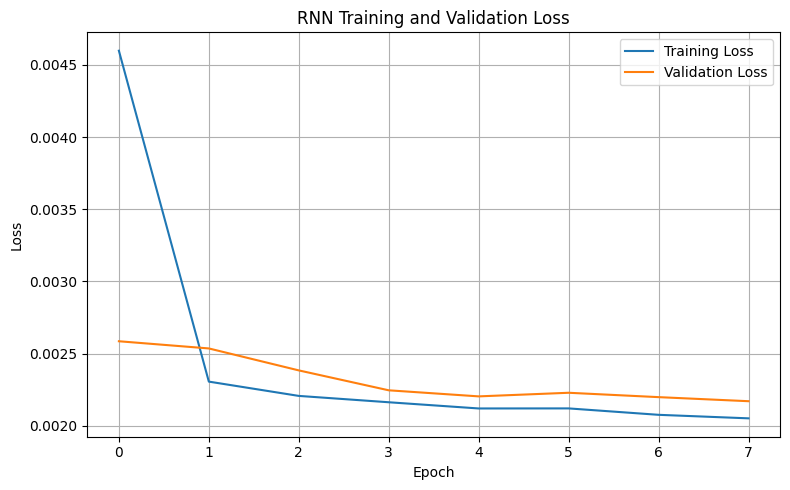

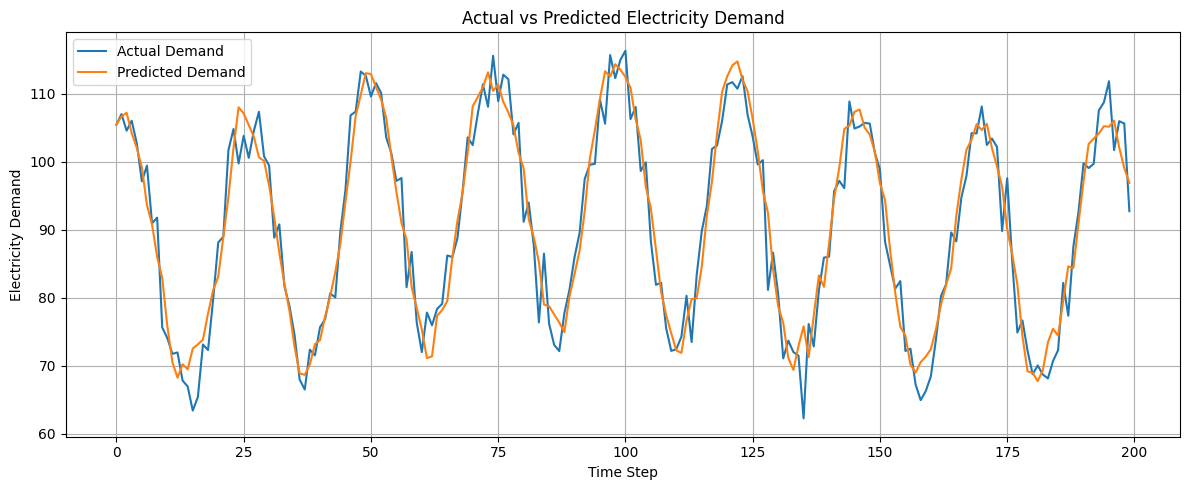


Sample Predictions:
   Actual Demand  Predicted Demand
0         105.45            105.50
1         107.02            106.66
2         104.58            107.22
3         106.04            104.22
4         102.74            102.05
5          97.12             99.17
6          99.44             93.63
7          90.94             90.76
8          91.79             86.05
9          75.64             82.91

Experiment 13 completed successfully!


In [17]:
# EXPERIMENT 13: SEQUENTIAL DATASET PREPARATION AND RNN PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ----------------------------------------
# 1. CREATE HOURLY ELECTRICITY DATA
# ----------------------------------------

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

hours = 24 * 365

date = pd.date_range(
    start="2025-01-01",
    periods=hours,
    freq="h"
)

hour_of_day = np.arange(hours) % 24
day_of_year = np.arange(hours) / 24

# Simulated electricity demand
demand = (
    100
    + 20 * np.sin(2 * np.pi * hour_of_day / 24)
    + 10 * np.sin(2 * np.pi * day_of_year / 365)
    + 5 * np.sin(2 * np.pi * np.arange(hours) / (24 * 7))
    + np.random.normal(0, 3, hours)
)

df = pd.DataFrame({
    "Date": date,
    "Demand": demand
})

# ----------------------------------------
# 2. HANDLE MISSING VALUES
# ----------------------------------------

df["Demand"] = df["Demand"].fillna(
    df["Demand"].mean()
)

print("Dataset:")
print(df.head())

# ----------------------------------------
# 3. SCALE DATA
# ----------------------------------------

data = df["Demand"].values

minimum = data.min()
maximum = data.max()

scaled_data = (data - minimum) / (maximum - minimum)

# ----------------------------------------
# 4. CREATE SLIDING WINDOWS
# 24 HOURS -> NEXT HOUR
# ----------------------------------------

window_size = 24

X = []
y = []

for i in range(window_size, len(scaled_data)):

    X.append(scaled_data[i-window_size:i])
    y.append(scaled_data[i])

X = np.array(X)
y = np.array(y)

X = X.reshape(X.shape[0], X.shape[1], 1)

# ----------------------------------------
# 5. CHRONOLOGICAL TRAIN-TEST SPLIT
# ----------------------------------------

split = int(len(X) * 0.8)

X_train = X[:split]
y_train = y[:split]

X_test = X[split:]
y_test = y[split:]

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ----------------------------------------
# 6. BUILD SIMPLE RNN MODEL
# ----------------------------------------

model = Sequential([
    SimpleRNN(32, activation="tanh",
              input_shape=(24, 1)),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

# ----------------------------------------
# 7. TRAIN THE MODEL
# ----------------------------------------

start_time = time.time()

history = model.fit(
    X_train, y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

training_time = time.time() - start_time

print("\nTraining Time:", round(training_time, 2), "seconds")

# ----------------------------------------
# 8. PREDICT TEST DATA
# ----------------------------------------

predictions = model.predict(X_test, verbose=0)

# Reverse scaling
predictions = predictions.flatten() * (maximum - minimum) + minimum

actual = y_test * (maximum - minimum) + minimum

# ----------------------------------------
# 9. CALCULATE MAE AND RMSE
# ----------------------------------------

mae = mean_absolute_error(actual, predictions)

rmse = np.sqrt(mean_squared_error(actual, predictions))

print("\nEVALUATION RESULTS")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

# ----------------------------------------
# 10. PLOT TRAINING AND VALIDATION LOSS
# ----------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("RNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------------------------------
# 11. ACTUAL VS PREDICTED DEMAND
# ----------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(actual[:200], label="Actual Demand")
plt.plot(predictions[:200], label="Predicted Demand")

plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Time Step")
plt.ylabel("Electricity Demand")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------------------------------
# 12. DISPLAY PREDICTION VALUES
# ----------------------------------------

result_df = pd.DataFrame({
    "Actual Demand": actual[:10],
    "Predicted Demand": predictions[:10]
})

print("\nSample Predictions:")
print(result_df.round(2))

print("\nExperiment 13 completed successfully!")